# 03 - Train and compare classical audio classifiers

This notebook trains a Linear Support Vector Machine and a Random Forest using the MFCC features created in notebook 02. It uses the training split for fitting and the validation split for model selection. The test split is deliberately held back for the final evaluation stage.

Both models use class weighting to reduce the effect of the uneven class distribution.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import (
    train_and_evaluate,
    evaluate_classifier,
    save_model_bundle,
    save_metrics,
)

DATA_DIR = PROJECT_ROOT / "notebooks" / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_PATH = DATA_DIR / "mfcc_features.npz"
if not FEATURE_PATH.is_file():
    raise FileNotFoundError("MFCC feature file missing. Run notebooks 01 and 02 first.")

print("Project root:", PROJECT_ROOT)
print("Feature archive:", FEATURE_PATH)

Project root: c:\Users\a\Documents\machine_learning_cycle
Feature archive: c:\Users\a\Documents\machine_learning_cycle\notebooks\data\processed\mfcc_features.npz


## 2. Load the prepared train, validation and test arrays

In [2]:
with np.load(FEATURE_PATH, allow_pickle=True) as data:
    X_train = data["X_train"].astype(np.float32)
    # Notebook 02 originally stored labels as object arrays. Convert them to
    # plain Unicode strings immediately after loading the trusted local file.
    y_train = np.asarray(data["y_train"], dtype=str)
    X_validation = data["X_validation"].astype(np.float32)
    y_validation = np.asarray(data["y_validation"], dtype=str)
    X_test = data["X_test"].astype(np.float32)
    y_test = np.asarray(data["y_test"], dtype=str)
    feature_names = data["feature_names"].astype(str)

print("Training:", X_train.shape, pd.Series(y_train).value_counts().to_dict())
print("Validation:", X_validation.shape)
print("Test (held back):", X_test.shape)
assert X_train.shape[1] == X_validation.shape[1] == X_test.shape[1] == len(feature_names)
assert np.isfinite(X_train).all() and np.isfinite(X_validation).all() and np.isfinite(X_test).all()

Training: (85120, 80) {'unknown': 54074, 'yes': 3228, 'down': 3134, 'no': 3130, 'stop': 3111, 'go': 3106, 'on': 3086, 'left': 3037, 'right': 3019, 'off': 2970, 'up': 2948, 'silence': 277}
Validation: (10042, 80)
Test (held back): (11065, 80)


## 3. Train the two baseline models

In [3]:
fitted_models, comparison = train_and_evaluate(
    X_train, y_train, X_validation, y_validation, random_state=42
)
display(comparison.round(4))

metrics_path = save_metrics(comparison, MODEL_DIR / "validation_model_comparison.json")
print("Saved validation comparison:", metrics_path)

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_seconds,validation_prediction_seconds
0,linear_svm,0.5132,0.5089,0.3648,0.5089,0.4052,0.5367,19.9817,0.2929
1,random_forest,0.6488,0.2019,0.7667,0.2019,0.2229,0.5298,275.2528,2.5762


Saved validation comparison: c:\Users\a\Documents\machine_learning_cycle\models\validation_model_comparison.json


## 4. Inspect per-class performance

\nlinear_svm per-class report


,precision,recall,f1-score,support
down,0.247,0.443,0.317,377.000
go,0.279,0.315,0.295,372.000
left,0.268,0.540,0.358,352.000
no,0.286,0.232,0.256,406.000
off,0.304,0.555,0.393,373.000
on,0.303,0.534,0.386,363.000
right,0.280,0.121,0.169,363.000
silence,0.649,1.000,0.787,61.000
stop,0.306,0.546,0.392,350.000
unknown,0.805,0.544,0.649,6278.000


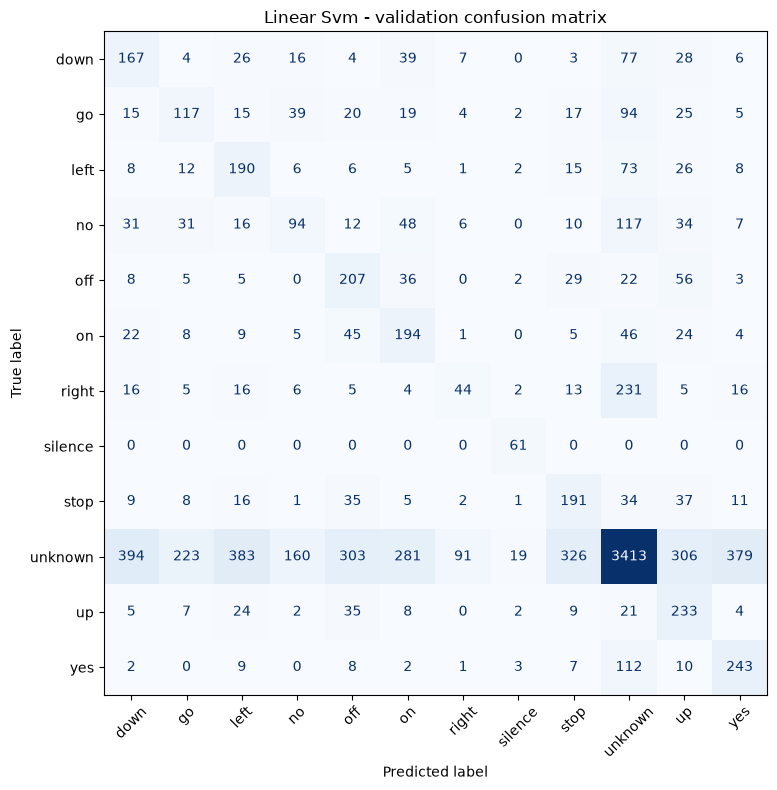

\nrandom_forest per-class report


,precision,recall,f1-score,support
down,1.000,0.003,0.005,377.000
go,1.000,0.003,0.005,372.000
left,1.000,0.003,0.006,352.000
no,0.000,0.000,0.000,406.000
off,0.806,0.201,0.322,373.000
on,0.833,0.028,0.053,363.000
right,0.500,0.003,0.005,363.000
silence,1.000,0.836,0.911,61.000
stop,0.786,0.094,0.168,350.000
unknown,0.643,0.995,0.782,6278.000


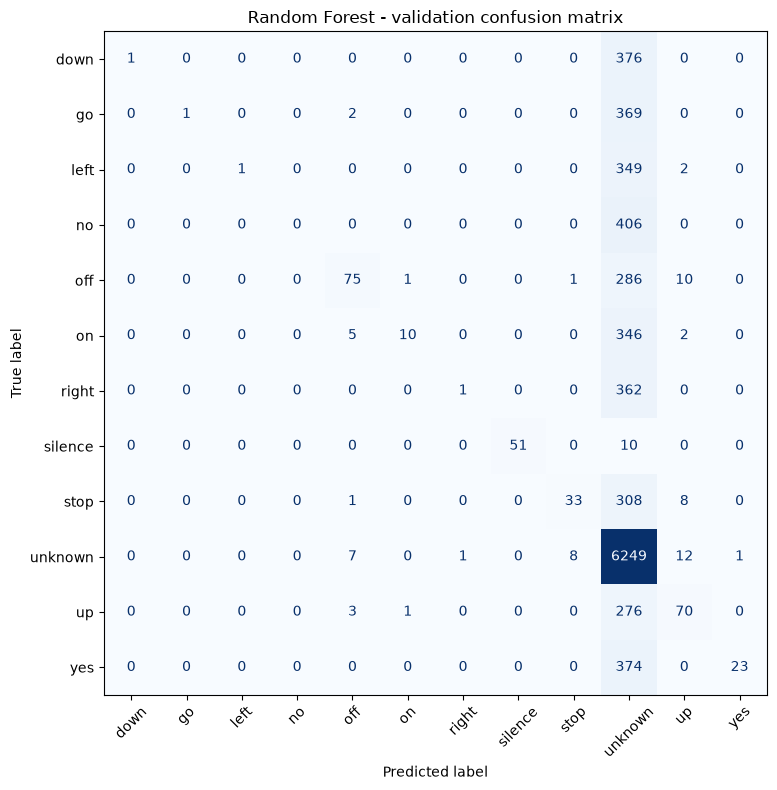

In [4]:
validation_results = {}
for model_name, model in fitted_models.items():
    result = evaluate_classifier(model, X_validation, y_validation)
    validation_results[model_name] = result
    print(f"\\n{model_name} per-class report")
    display(pd.DataFrame(result["report"]).T.round(3))

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=result["labels"],
    ).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
    ax.set_title(f"{model_name.replace('_', ' ').title()} - validation confusion matrix")
    plt.tight_layout()
    plt.show()

## 5. Save the best validation model

In [5]:
best_model_name = str(comparison.iloc[0]["model"])
best_model = fitted_models[best_model_name]

# Save both fitted classical models so the final test notebook can compare
# SVM and Random Forest without retraining or selecting on the test set.
for model_name, fitted_model in fitted_models.items():
    bundle_path = save_model_bundle(
        fitted_model,
        MODEL_DIR / f"{model_name}.joblib",
        model_name=model_name,
        feature_names=feature_names,
    )
    print(f"Saved {model_name} bundle:", bundle_path)

print("Best classical model by validation macro-F1:", best_model_name)
print("Validation macro-F1:", round(float(comparison.iloc[0]["macro_f1"]), 4))
print("\nBoth classical models are saved. The test split remains untouched.")

Saved linear_svm bundle: c:\Users\a\Documents\machine_learning_cycle\models\linear_svm.joblib
Saved random_forest bundle: c:\Users\a\Documents\machine_learning_cycle\models\random_forest.joblib
Best classical model by validation macro-F1: linear_svm
Validation macro-F1: 0.4052

Both classical models are saved. The test split remains untouched.


## 6. What to record from this experiment

Compare macro-F1 and balanced accuracy rather than relying on accuracy alone. Macro-F1 gives every command class equal weight, which matters because `unknown` has many more examples than most individual commands. Review the confusion matrices to see which commands are commonly mixed up. Training and validation prediction times provide an initial efficiency comparison.

The saved model is a baseline artifact. The CNN experiment will be added separately, and the final test set will be used only after model selection is complete.